# 02 · Mixture of Factor Analyzers — EM and BIC selection
Custom NumPy implementation in `src/mfa.py`; low-rank algebra in `src/woodbury.py`.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

## Woodbury identity check

In [2]:
from src.woodbury import WoodburyFactor
rng = np.random.default_rng(0); d, r = 384, 16
f = WoodburyFactor.build(rng.normal(size=d), rng.normal(size=(d, r))*.05, rng.uniform(1e-3, 3e-3, d))
S = f.W @ f.W.T + np.diag(f.psi)
print('max |Woodbury - inv| =', np.abs(f.precision() - np.linalg.inv(S)).max())
print('logdet error =', abs(f.log_det - np.linalg.slogdet(S)[1]))

max |Woodbury - inv| = 3.6500580335996347e-11
logdet error = 9.094947017729282e-13


## Fit one MFA live (K = 8, r = 16) on training passages

In [3]:
from src.mfa import MFA
split = np.load('data/train_val_split.npz')
X = np.load('data/corpus_embeddings.npy').astype(float)
Xtr = X[split['train_idx']]
m = MFA(8, 16, verbose=True).fit(Xtr)
print(f'{m.n_iter_} iterations, converged={m.converged_}, {m.fit_time_:.1f}s, params={m.n_parameters():,}')
print('full-cov GMM params would be', 8*(384*385//2 + 384) + 7)

  iter   1  logL = 4,100,152.68


  iter   2  logL = 4,111,389.71


  iter   3  logL = 4,114,759.03


  iter   4  logL = 4,116,276.45


  iter   5  logL = 4,117,125.27


  iter   6  logL = 4,117,726.81


... (11 outputs left out)

  iter  18  logL = 4,121,087.78


  iter  19  logL = 4,121,157.98


  iter  20  logL = 4,121,213.95


  iter  21  logL = 4,121,247.73
21 iterations, converged=True, 12.0s, params=54,343
full-cov GMM params would be 594439


## BIC grid (K × r) for both fitting sources

In [4]:
bic = pd.read_csv('results/bic_grid.csv'); bic.round(1)

,source,K,r,log_likelihood,n_params,BIC,iterations,converged,fit_seconds
0,passage,2,8,3787101.0,7625,-7509114.9,9,True,2.6
1,passage,2,16,3914358.0,13585,-7712754.2,16,True,2.5
2,passage,2,32,4070819.0,25121,-7927204.7,23,True,3.6
3,passage,2,64,4264443.0,46657,-8130621.1,20,True,5.9
4,passage,4,8,3863239.2,15251,-7596295.7,21,True,7.3
5,passage,4,16,4008046.1,27171,-7784160.1,27,True,8.2
6,passage,4,32,4191170.3,50243,-7953465.6,19,True,7.4
7,passage,4,64,4416957.1,93315,-8037376.0,27,True,8.7
8,passage,8,8,3957323.8,30503,-7654273.6,46,True,23.8
9,passage,8,16,4121247.7,54343,-7778622.8,21,True,13.1


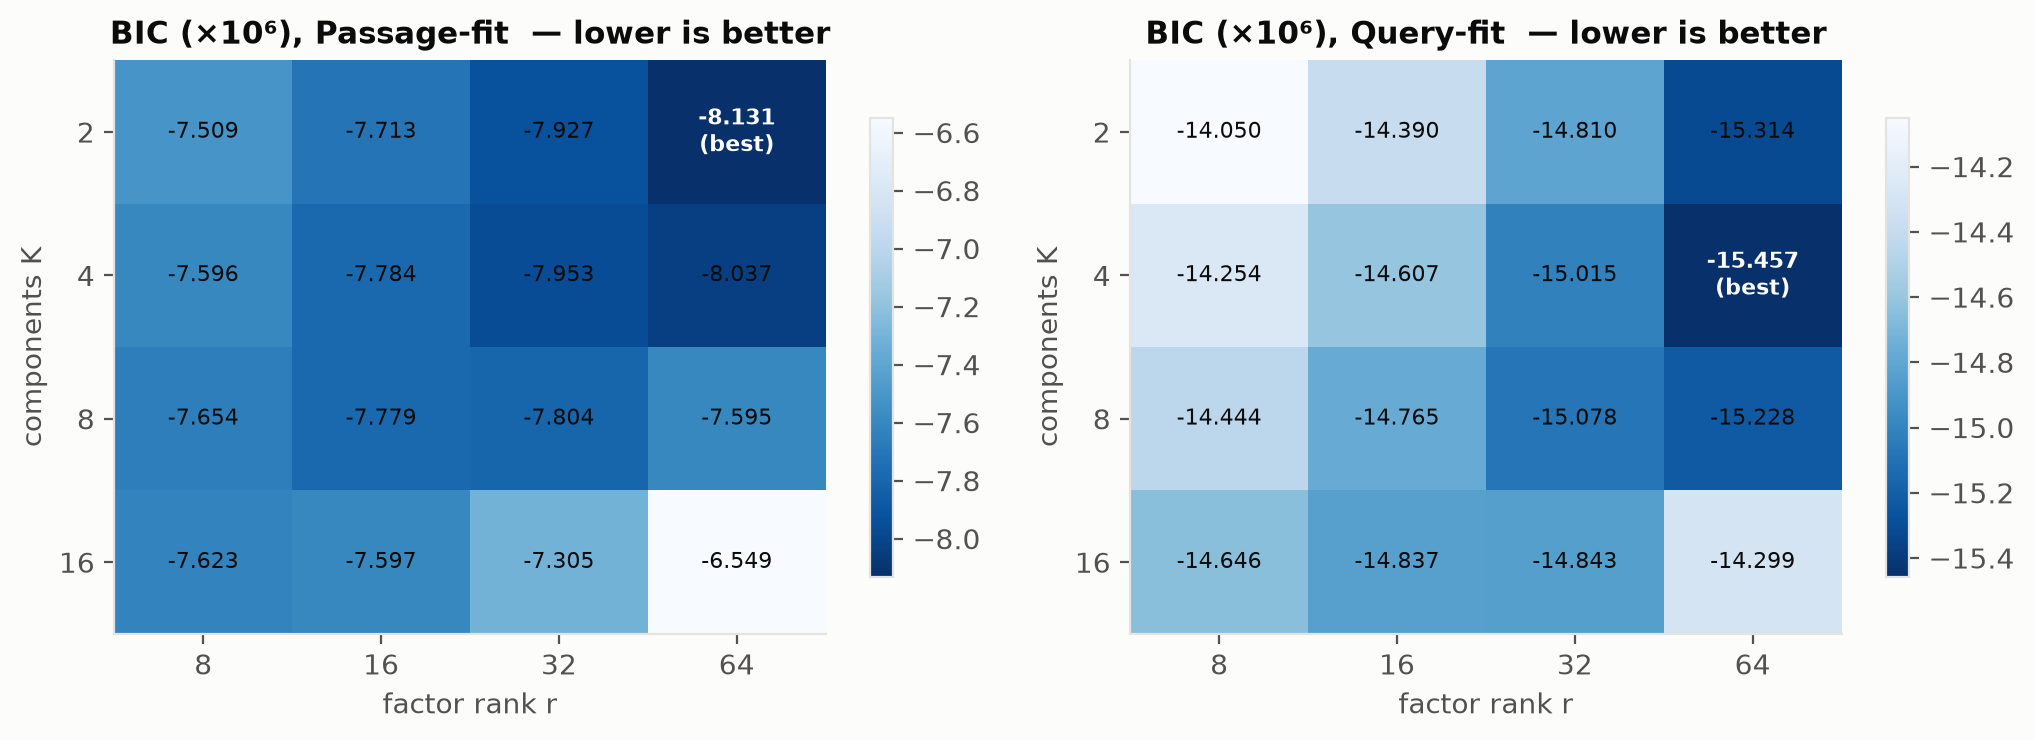

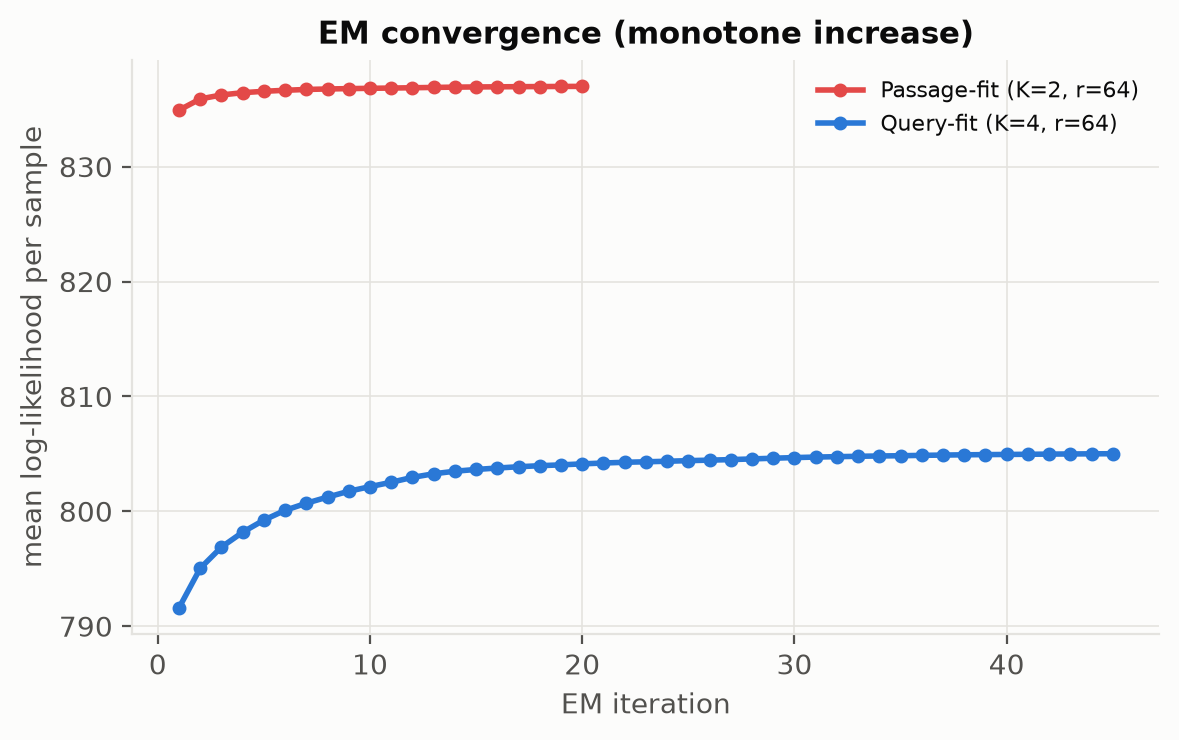

In [5]:
display(Image('results/bic_heatmap.png'))
display(Image('results/em_loglik.png'))

In [6]:
json.load(open('results/summary.json'))['sources']

{'passage': {'K': 2,
  'r': 64,
  'n_train': 5095,
  'n_val': 1273,
  'mfa_params': 46657,
  'full_gmm_params': 148609,
  'evt': {'tau0': 584.042018179798,
   'kappa': 1.0112160453753845,
   'lambda': 92.48814475572411,
   'ks_pvalue': 0.4871416200569223,
   'threshold_at_alpha': 1002.8117358972966},
  'em_iterations': 20,
  'em_converged': True},
 'query': {'K': 4,
  'r': 64,
  'n_train': 10135,
  'n_val': 2533,
  'mfa_params': 93315,
  'full_gmm_params': 297219,
  'evt': {'tau0': 501.8868260440485,
   'kappa': 1.0574919291775382,
   'lambda': 52.91170735749897,
   'ks_pvalue': 0.7359552891002347,
   'threshold_at_alpha': 726.140332538467},
  'em_iterations': 45,
  'em_converged': True}}